In [4]:
import os
import numpy as nm
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [5]:
df = pd.read_csv(r"C:\Users\MUKTADIR NISHAT\Downloads\hospital_data_unclean.csv")
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,NaN,30.0,M,B-,CANCER,2024.01.31,Matthew Smith ##,"Sons and Miller,,",Blue Cross,18856.281305978155 USD,328.0,Urgent,02/02/2024,Paracetamol,N
1,LEsliE tErrY,62.0,M,A+,OBESITY,2019.08.20,Samantha Davies ##,"Kim Inc,,",Medicare,33643.327286577885 USD,265.0,Emergency,26-08-2019,Ibuprofen,unknown
2,dAnnY SMiTH,76.0,FEMALE,A-,OBESITY,09/22/2022,NaN,"Cook PLC,,",Aetna,27955.096078842456 USD,205.0,Emergency,07-10-2022,Aspirin,N
3,NaN,28.0,FEMALE,O+,DIABETES,11/18/2020,Kevin Wells ##,"Hernandez Rogers and Vang,,,",Medicare,37909.78240987528 USD,450.0,Elective,2020.12.18,Ibuprofen,abn
4,ADRIeNNe bELL,43.0,FEMALE,AB+-,CANCER,2022.09.19,Kathleen Hanna ##,NaN,NaN,14238.317813937623 USD,458.0,Urgent,10/09/2022,Penicillin,abn


In [6]:
df.shape

(55505, 15)

In [7]:
df.isna().sum()

Name                  4440
Age                   4440
Gender                4440
Blood Type            4440
Medical Condition     4440
Date of Admission     4440
Doctor                4440
Hospital              4441
Insurance Provider    4442
Billing Amount        4440
Room Number           4441
Admission Type        4440
Discharge Date        4441
Medication            4440
Test Results          4440
dtype: int64

In [12]:
df['Name'] = df['Name'].str.title()
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,NaN,30.0,Male,B-,CANCER,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281305978155 USD,328.0,Urgent,02-02-2024,Paracetamol,N
1,Leslie Terry,62.0,Male,A+,OBESITY,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327286577885 USD,265.0,Emergency,26-08-2019,Ibuprofen,unknown
2,Danny Smith,76.0,Female,A-,OBESITY,09-22-2022,NaN,Cook PLC,Aetna,27955.096078842456 USD,205.0,Emergency,07-10-2022,Aspirin,N
3,NaN,28.0,Female,O+,DIABETES,11-18-2020,Kevin Wells,Hernandez Rogers and Vang,Medicare,37909.78240987528 USD,450.0,Elective,2020-12-18,Ibuprofen,abn
4,Adrienne Bell,43.0,Female,AB+-,CANCER,2022-09-19,Kathleen Hanna,NaN,NaN,14238.317813937623 USD,458.0,Urgent,10-09-2022,Penicillin,abn


In [17]:
df['Gender'] = df['Gender'].replace({'MALE': 'Male', 'F': 'Female'})
df['Gender'].value_counts()

Gender
Male      25605
Female    25460
Name: count, dtype: int64

In [19]:
df['Date of Admission'] = df['Date of Admission'].astype(str)
df['Discharge Date'] = df['Discharge Date'].astype(str)

df['Date of Admission'] = df['Date of Admission'].str.replace('.', '-', regex=False)
df['Date of Admission'] = df['Date of Admission'].str.replace('/', '-', regex=False)

df['Discharge Date'] = df['Discharge Date'].str.replace('.', '-', regex=False)
df['Discharge Date'] = df['Discharge Date'].str.replace('/', '-', regex=False)
df[['Date of Admission', 'Discharge Date']].head()

,Date of Admission,Discharge Date
0,2024-01-31,02-02-2024
1,2019-08-20,26-08-2019
2,09-22-2022,07-10-2022
3,11-18-2020,2020-12-18
4,2022-09-19,10-09-2022


In [20]:
df['Doctor'] = df['Doctor'].str.replace('#', '', regex=False)
df['Hospital'] = df['Hospital'].str.replace(',', '', regex=False)
df[['Doctor', 'Hospital']].head()

,Doctor,Hospital
0,Matthew Smith,Sons and Miller
1,Samantha Davies,Kim Inc
2,NaN,Cook PLC
3,Kevin Wells,Hernandez Rogers and Vang
4,Kathleen Hanna,NaN


In [21]:
df['Insurance Provider'] = df['Insurance Provider'].str.replace('H', ' H', regex=False)

df['Insurance Provider'].unique()

<StringArray>
['Blue Cross', 'Medicare', 'Aetna', nan, 'United Healthcare', 'Cigna']
Length: 6, dtype: str

In [22]:
df['Name'].fillna('Unknown', inplace=True)
df['Age'].fillna(df['Age'].mean(), inplace=True)
df['Gender'].fillna(df['Gender'].mode()[0], inplace=True)
df['Blood Type'].fillna(df['Blood Type'].mode()[0], inplace=True)

df[['Name', 'Age', 'Gender', 'Blood Type']].isna().sum()

C:\Users\MUKTADIR NISHAT\AppData\Local\Temp\ipykernel_10180\2590778605.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  df['Name'].fillna('Unknown', inplace=True)
C:\Users\MUKTADIR NISHAT\AppData\Local\Temp\ipykernel_10180\2590778605.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through 

Name          4440
Age           4440
Gender        4440
Blood Type    4440
dtype: int64

In [23]:
df['Doctor'].fillna('Unknown', inplace=True)
df['Medical Condition'].fillna('Unknown', inplace=True)
df['Hospital'].fillna('Unknown', inplace=True)
df['Insurance Provider'].fillna('Unknown', inplace=True)

df[['Doctor', 'Medical Condition', 'Hospital', 'Insurance Provider']].isna().sum()

C:\Users\MUKTADIR NISHAT\AppData\Local\Temp\ipykernel_10180\1096523376.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  df['Doctor'].fillna('Unknown', inplace=True)
C:\Users\MUKTADIR NISHAT\AppData\Local\Temp\ipykernel_10180\1096523376.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series throug

Doctor                4440
Medical Condition     4440
Hospital              4441
Insurance Provider    4442
dtype: int64

In [24]:
df['Billing Amount'] = df['Billing Amount'].astype(str)
df['Billing Amount'] = df['Billing Amount'].str.replace(' USD', '', regex=False)
df['Billing Amount'] = df['Billing Amount'].astype(float)
df['Billing Amount'].fillna(df['Billing Amount'].mean(), inplace=True)

df['Billing Amount'].head()

C:\Users\MUKTADIR NISHAT\AppData\Local\Temp\ipykernel_10180\1851064907.py:4: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  df['Billing Amount'].fillna(df['Billing Amount'].mean(), inplace=True)


0    18856.281306
1    33643.327287
2    27955.096079
3    37909.782410
4    14238.317814
Name: Billing Amount, dtype: float64

In [25]:
df['Billing Amount'] = df['Billing Amount'].astype(str)
df['Billing Amount'] = df['Billing Amount'].str.replace(' USD', '', regex=False)
df['Billing Amount'] = df['Billing Amount'].astype(float)
df['Billing Amount'].fillna(df['Billing Amount'].mean(), inplace=True)

df['Billing Amount'].head()

C:\Users\MUKTADIR NISHAT\AppData\Local\Temp\ipykernel_10180\1851064907.py:4: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  df['Billing Amount'].fillna(df['Billing Amount'].mean(), inplace=True)


0    18856.281306
1    33643.327287
2    27955.096079
3    37909.782410
4    14238.317814
Name: Billing Amount, dtype: float64

In [28]:
df['Medication'] = df['Medication'].fillna('Unknown')

df['Test Results'] = df['Test Results'].fillna('Unknown')
df['Test Results'] = df['Test Results'].str.replace('u', 'U', regex=False)
df['Test Results'] = df['Test Results'].replace({'abn': 'Abnormal', 'ABN': 'Abnormal', 'N': 'Normal'})

df['Test Results'].value_counts()

Test Results
Unknown     21343
Abnormal    17123
Normal      17039
Name: count, dtype: int64

In [29]:
df['Room Number'] = df['Room Number'].fillna('Not Assign')
df['Admission Type'] = df['Admission Type'].fillna('Unknown')

df.isna().sum()

C:\Users\MUKTADIR NISHAT\AppData\Local\Temp\ipykernel_10180\4003224656.py:1: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  df['Room Number'] = df['Room Number'].fillna('Not Assign')


Name                  4440
Age                   4440
Gender                4440
Blood Type            4440
Medical Condition     4440
Date of Admission     4440
Doctor                4440
Hospital              4441
Insurance Provider    4442
Billing Amount        4440
Room Number              0
Admission Type           0
Discharge Date        4441
Medication               0
Test Results             0
dtype: int64

In [30]:
df['Date of Admission'] = df['Date of Admission'].astype(str).str.strip()
df['Discharge Date'] = df['Discharge Date'].astype(str).str.strip()

# Clean Date of Admission
dates = pd.to_datetime(df['Date of Admission'], errors='coerce')
mask = dates.isna()
dates[mask] = pd.to_datetime(df.loc[mask, 'Date of Admission'], errors='coerce', dayfirst=True)
df['Date of Admission'] = dates
df['Date of Admission'] = df['Date of Admission'].fillna(df['Date of Admission'].median())

# Clean Discharge Date
dates_dis = pd.to_datetime(df['Discharge Date'], errors='coerce')
mask_dis = dates_dis.isna()
dates_dis[mask_dis] = pd.to_datetime(df.loc[mask_dis, 'Discharge Date'], errors='coerce', dayfirst=True)
df['Discharge Date'] = dates_dis
df['Discharge Date'] = df['Discharge Date'].fillna(df['Discharge Date'].median())

df[['Date of Admission', 'Discharge Date']].head()

C:\Users\MUKTADIR NISHAT\AppData\Local\Temp\ipykernel_10180\1309536395.py:7: UserWarning: Parsing dates in %m-%d-%Y format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  dates[mask] = pd.to_datetime(df.loc[mask, 'Date of Admission'], errors='coerce', dayfirst=True)


,Date of Admission,Discharge Date
0,2024-01-31,2024-02-02
1,2019-08-20,2019-08-26
2,2022-09-22,2022-07-10
3,2020-11-18,2021-11-16
4,2022-09-19,2022-10-09


In [31]:
df['Blood Type'] = df['Blood Type'].astype(str).str.strip().str.upper()
df['Blood Type'] = df['Blood Type'].str.replace(r'[+-]+', lambda x: x.group(0)[0], regex=True)

df['Blood Type'].value_counts()

Blood Type
B-     6438
A-     6428
A+     6403
AB+    6385
B+     6380
AB-    6377
O+     6348
O-     6306
Name: count, dtype: int64

In [32]:
df['Billing Amount'] = df['Billing Amount'].round(2)
df.to_excel('hospital.xlsx', index=False)

df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,NaN,30.0,Male,B-,CANCER,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.28,328.0,Urgent,2024-02-02,Paracetamol,Normal
1,Leslie Terry,62.0,Male,A+,OBESITY,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.33,265.0,Emergency,2019-08-26,Ibuprofen,Unknown
2,Danny Smith,76.0,Female,A-,OBESITY,2022-09-22,NaN,Cook PLC,Aetna,27955.10,205.0,Emergency,2022-07-10,Aspirin,Normal
3,NaN,28.0,Female,O+,DIABETES,2020-11-18,Kevin Wells,Hernandez Rogers and Vang,Medicare,37909.78,450.0,Elective,2021-11-16,Ibuprofen,Abnormal
4,Adrienne Bell,43.0,Female,AB+,CANCER,2022-09-19,Kathleen Hanna,NaN,NaN,14238.32,458.0,Urgent,2022-10-09,Penicillin,Abnormal


In [33]:
df['Date of Admission'] = pd.to_datetime(df['Date of Admission'])
df['Discharge Date'] = pd.to_datetime(df['Discharge Date'])
df['Stay_Days'] = (df['Discharge Date'] - df['Date of Admission']).dt.days
df['Admission_Year'] = df['Date of Admission'].dt.year

df[['Age', 'Billing Amount', 'Stay_Days']].describe().round(2)

,Age,Billing Amount,Stay_Days
count,51065.00,51065.00,55505.00
mean,51.58,25553.79,15.75
std,19.59,14211.22,359.23
min,13.00,-2008.49,-1114.00
25%,35.00,13250.28,-60.00
50%,52.00,25593.00,15.00
75%,68.00,37806.97,92.00
max,89.00,52764.28,1130.00


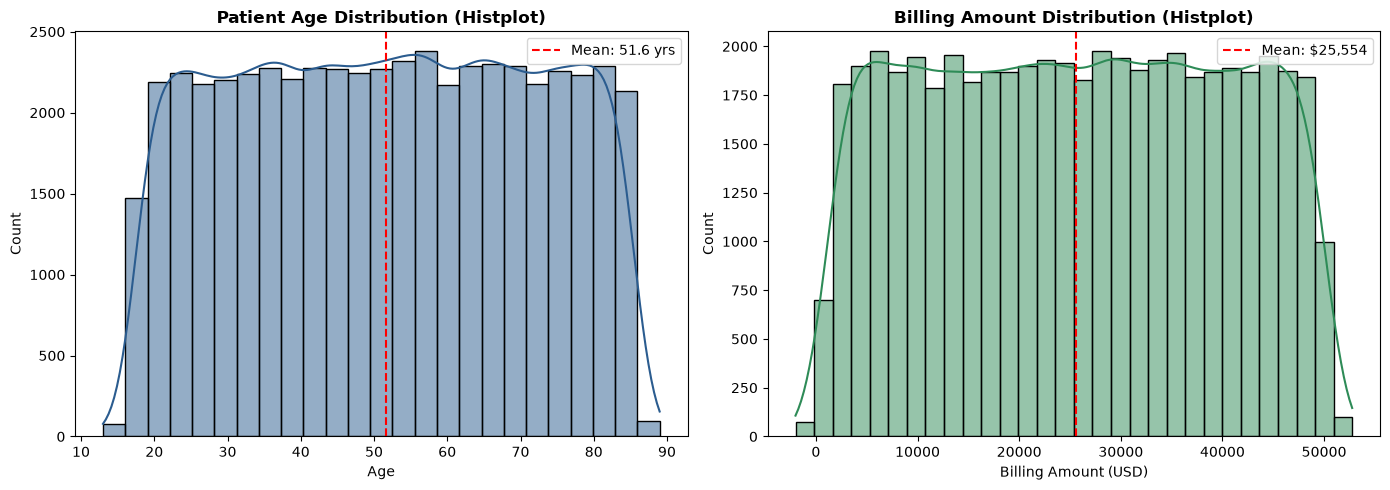

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Age Histplot
sns.histplot(df['Age'], bins=25, kde=True, color='#2b5c8f', ax=axes[0])
axes[0].axvline(df['Age'].mean(), color='red', linestyle='--', label=f"Mean: {df['Age'].mean():.1f} yrs")
axes[0].set_title('Patient Age Distribution (Histplot)', fontweight='bold')
axes[0].set_xlabel('Age')
axes[0].legend()

# Billing Amount Histplot
sns.histplot(df['Billing Amount'], bins=30, kde=True, color='#2e8b57', ax=axes[1])
axes[1].axvline(df['Billing Amount'].mean(), color='red', linestyle='--', label=f"Mean: ${df['Billing Amount'].mean():,.0f}")
axes[1].set_title('Billing Amount Distribution (Histplot)', fontweight='bold')
axes[1].set_xlabel('Billing Amount (USD)')
axes[1].legend()

plt.tight_layout()
plt.savefig('01_histplots.png', dpi=300)
plt.show()

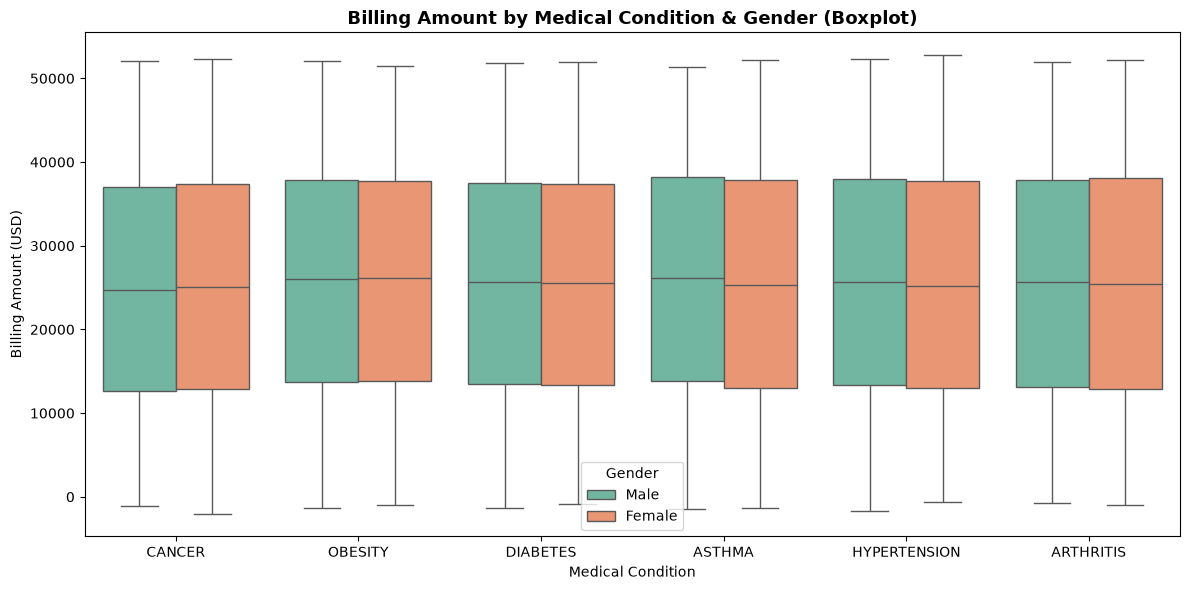

In [35]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df[df['Medical Condition'] != 'Unknown'],
    x='Medical Condition',
    y='Billing Amount',
    hue='Gender',
    palette='Set2'
)

plt.title('Billing Amount by Medical Condition & Gender (Boxplot)', fontsize=13, fontweight='bold')
plt.xlabel('Medical Condition')
plt.ylabel('Billing Amount (USD)')
plt.tight_layout()
plt.savefig('02_boxplot_condition_gender.png', dpi=300)
plt.show()

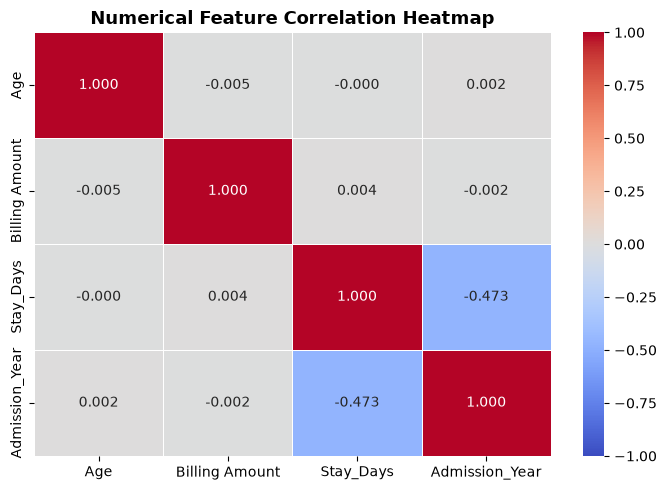

In [36]:
plt.figure(figsize=(7, 5))

corr_matrix = df[['Age', 'Billing Amount', 'Stay_Days', 'Admission_Year']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.5, vmin=-1, vmax=1)

plt.title('Numerical Feature Correlation Heatmap', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('03_correlation_heatmap.png', dpi=300)
plt.show()

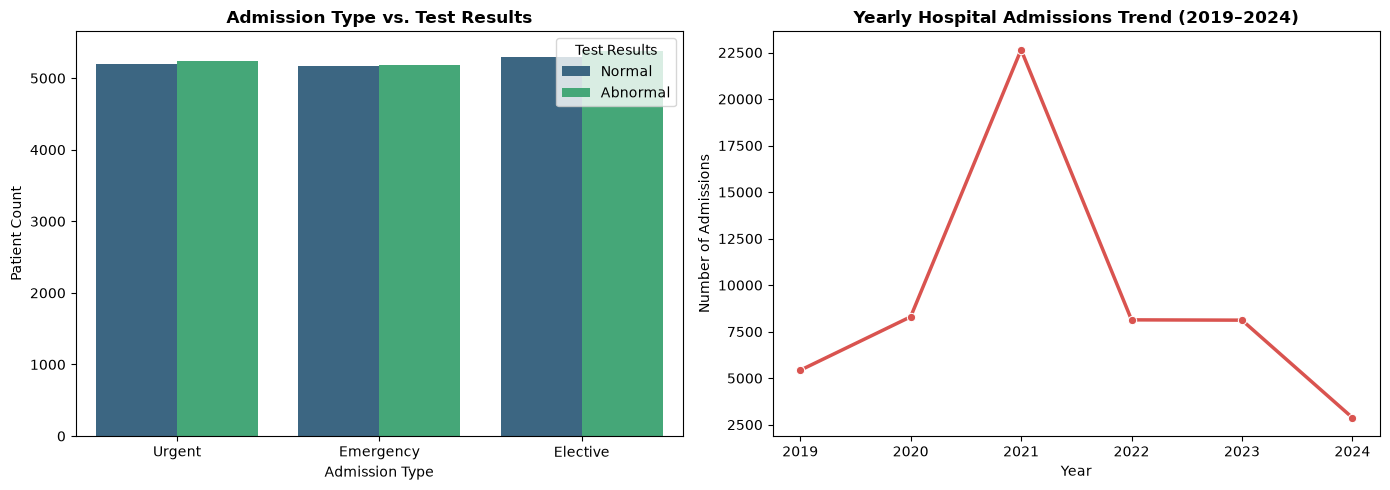

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Admission Type vs Test Results
sns.countplot(
    data=df[(df['Admission Type'] != 'Unknown') & (df['Test Results'] != 'Unknown')],
    x='Admission Type',
    hue='Test Results',
    palette='viridis',
    ax=axes[0]
)
axes[0].set_title('Admission Type vs. Test Results', fontweight='bold')
axes[0].set_ylabel('Patient Count')

# Yearly Admissions Trend
yearly = df['Admission_Year'].value_counts().sort_index()
sns.lineplot(x=yearly.index, y=yearly.values, marker='o', linewidth=2.5, color='#d9534f', ax=axes[1])
axes[1].set_title('Yearly Hospital Admissions Trend (2019–2024)', fontweight='bold')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Number of Admissions')

plt.tight_layout()
plt.savefig('04_categorical_and_trend.png', dpi=300)
plt.show()

In [39]:
print("Billing Summary by Medical Condition")
display(
    df[df['Medical Condition'] != 'Unknown']
    .groupby('Medical Condition')['Billing Amount']
    .agg(['count', 'mean', 'median', 'std'])
    .round(2)
)

print("Admission Type vs Test Results")
display(pd.crosstab(
    df[df['Admission Type'] != 'Unknown']['Admission Type'],
    df[df['Test Results'] != 'Unknown']['Test Results']
))

Billing Summary by Medical Condition


,count,mean,median,std
Medical Condition,,,,
ARTHRITIS,7936,25498.33,25602.15,14299.63
ASTHMA,7741,25725.84,25829.06,14215.21
CANCER,7785,25064.78,24815.51,14247.84
DIABETES,7910,25593.58,25615.50,14135.16
HYPERTENSION,7817,25561.15,25487.49,14314.37
OBESITY,7805,25759.81,26073.81,14090.95


Admission Type vs Test Results


Test Results,Abnormal,Normal
Admission Type,,
Elective,5385,5292
Emergency,5187,5165
Urgent,5233,5198
